In [50]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

In [18]:
csv_path = "../data/PRSA_Data_Aotizhongxin_20130301-20170228.csv"
df = pd.read_csv(csv_path)

df["timestamp"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.sort_values("timestamp").reset_index(drop=True)

In [19]:
print("Kronolojik mi?:", df["timestamp"].is_monotonic_increasing)
print("Tekrarlanan saat:", df["timestamp"].duplicated().sum())
print("Toplam kayıt:", len(df))
print("İlk tarih:", df["timestamp"].min())
print("Son tarih:", df["timestamp"].max())

assert df["timestamp"].is_monotonic_increasing
assert not df["timestamp"].duplicated().any(), "Tekrarlanan saatler var; önce incele."

Kronolojik mi?: True
Tekrarlanan saat: 0
Toplam kayıt: 35064
İlk tarih: 2013-03-01 00:00:00
Son tarih: 2017-02-28 23:00:00


In [20]:
df["target_timestamp"] = df["timestamp"].shift(-1)
df["target_pm25_next_hour"] = df["PM2.5"].shift(-1)

one_hour_gap = (
    df["target_timestamp"] - df["timestamp"] == pd.Timedelta(hours=1)
)

# Girdi ve hedef ölçümleri mevcut, saat farkı da tam 1 saat.
valid_rows = (
    one_hour_gap
    & df["PM2.5"].notna()
    & df["target_pm25_next_hour"].notna()
)

print("Geçerli saat çiftleri:", valid_rows.sum())
print("Geçersiz / eksik çiftler:", (~valid_rows).sum())

df[["timestamp", "PM2.5", "target_timestamp", "target_pm25_next_hour"]].head(5)

Geçerli saat çiftleri: 33929
Geçersiz / eksik çiftler: 1135


,timestamp,PM2.5,target_timestamp,target_pm25_next_hour
0,2013-03-01 00:00:00,4.0,2013-03-01 01:00:00,8.0
1,2013-03-01 01:00:00,8.0,2013-03-01 02:00:00,7.0
2,2013-03-01 02:00:00,7.0,2013-03-01 03:00:00,6.0
3,2013-03-01 03:00:00,6.0,2013-03-01 04:00:00,3.0
4,2013-03-01 04:00:00,3.0,2013-03-01 05:00:00,5.0


In [21]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

val_start_time = df.loc[train_end, "timestamp"]
test_start_time = df.loc[val_end, "timestamp"]

print("Ham dönem kayıtları:")
print("Train:", train_end)
print("Validation:", val_end - train_end)
print("Test:", n - val_end)
print()
print("Validation başlangıcı:", val_start_time)
print("Test başlangıcı:", test_start_time)


Ham dönem kayıtları:
Train: 24544
Validation: 5260
Test: 5260

Validation başlangıcı: 2015-12-18 16:00:00
Test başlangıcı: 2016-07-24 20:00:00


In [22]:
valid_pairs = df.loc[valid_rows].copy()

train_df = valid_pairs[
    valid_pairs["target_timestamp"] < val_start_time
].copy()

val_df = valid_pairs[
    (valid_pairs["target_timestamp"] >= val_start_time)
    & (valid_pairs["target_timestamp"] < test_start_time)
].copy()

test_df = valid_pairs[
    valid_pairs["target_timestamp"] >= test_start_time
].copy()

print("Geçerli tahmin çifti sayıları:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Toplam:", len(train_df) + len(val_df) + len(test_df))


Geçerli tahmin çifti sayıları:
Train: 23683
Validation: 5107
Test: 5139
Toplam: 33929


In [23]:
summary = pd.DataFrame({
    "Dönem": ["Train", "Validation", "Test"],
    "Kayıt sayısı": [len(train_df), len(val_df), len(test_df)],
    "İlk hedef saati": [
        train_df["target_timestamp"].min(),
        val_df["target_timestamp"].min(),
        test_df["target_timestamp"].min()
    ],
    "Son hedef saati": [
        train_df["target_timestamp"].max(),
        val_df["target_timestamp"].max(),
        test_df["target_timestamp"].max()
    ]
})

display(summary)

assert train_df["target_timestamp"].max() < val_df["target_timestamp"].min()
assert val_df["target_timestamp"].max() < test_df["target_timestamp"].min()
assert len(train_df) + len(val_df) + len(test_df) == len(valid_pairs)

print("Train / Validation çakışması: YOK")
print("Validation / Test çakışması: YOK")
print("Tüm geçerli hedefler tek bir dönemde: EVET")


,Dönem,Kayıt sayısı,İlk hedef saati,Son hedef saati
0,Train,23683,2013-03-01 01:00:00,2015-12-18 15:00:00
1,Validation,5107,2015-12-18 16:00:00,2016-07-24 19:00:00
2,Test,5139,2016-07-24 20:00:00,2017-02-28 23:00:00


Train / Validation çakışması: YOK
Validation / Test çakışması: YOK
Tüm geçerli hedefler tek bir dönemde: EVET


In [24]:
print("Train son 3 satır:")
display(train_df[["timestamp", "target_timestamp", "PM2.5", "target_pm25_next_hour"]].tail(3))

print("Validation ilk 3 satır:")
display(val_df[["timestamp", "target_timestamp", "PM2.5", "target_pm25_next_hour"]].head(3))


Train son 3 satır:


,timestamp,target_timestamp,PM2.5,target_pm25_next_hour
24540,2015-12-18 12:00:00,2015-12-18 13:00:00,30.0,23.0
24541,2015-12-18 13:00:00,2015-12-18 14:00:00,23.0,26.0
24542,2015-12-18 14:00:00,2015-12-18 15:00:00,26.0,28.0


Validation ilk 3 satır:


,timestamp,target_timestamp,PM2.5,target_pm25_next_hour
24543,2015-12-18 15:00:00,2015-12-18 16:00:00,28.0,24.0
24544,2015-12-18 16:00:00,2015-12-18 17:00:00,24.0,18.0
24545,2015-12-18 17:00:00,2015-12-18 18:00:00,18.0,24.0


In [25]:
def lag_features(dataframe, lags):
    for lag in lags:
        dataframe["pm25_lag_" + str(lag)] = dataframe["PM2.5"].shift(lag)
    return dataframe

In [26]:
df = lag_features(df, [1, 2, 3, 6, 12, 24])

In [28]:
df["pm25_current"] = df["PM2.5"]

In [29]:
df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,...,timestamp,target_timestamp,target_pm25_next_hour,pm25_lag_1,pm25_lag_2,pm25_lag_3,pm25_lag_6,pm25_lag_12,pm25_lag_24,pm25_current
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,...,2013-03-01 00:00:00,2013-03-01 01:00:00,8.0,NaN,NaN,NaN,NaN,NaN,NaN,4.0
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,...,2013-03-01 01:00:00,2013-03-01 02:00:00,7.0,4.0,NaN,NaN,NaN,NaN,NaN,8.0
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,...,2013-03-01 02:00:00,2013-03-01 03:00:00,6.0,8.0,4.0,NaN,NaN,NaN,NaN,7.0
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,...,2013-03-01 03:00:00,2013-03-01 04:00:00,3.0,7.0,8.0,4.0,NaN,NaN,NaN,6.0
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,...,2013-03-01 04:00:00,2013-03-01 05:00:00,5.0,6.0,7.0,8.0,NaN,NaN,NaN,3.0


In [31]:
df.isnull().sum()

No                          0
year                        0
month                       0
day                         0
hour                        0
PM2.5                     925
PM10                      718
SO2                       935
NO2                      1023
CO                       1776
O3                       1719
TEMP                       20
PRES                       20
DEWP                       20
RAIN                       20
wd                         81
WSPM                       14
station                     0
timestamp                   0
target_timestamp            1
target_pm25_next_hour     926
pm25_lag_1                926
pm25_lag_2                927
pm25_lag_3                928
pm25_lag_6                931
pm25_lag_12               937
pm25_lag_24               949
pm25_current              925
dtype: int64

In [32]:
valid_target_time = (
    df["target_timestamp"] - df["timestamp"]
    == pd.Timedelta(hours=1)
)

print("Geçerli hedef zamanı:", valid_target_time.sum())
print("Geçersiz hedef zamanı:", (~valid_target_time).sum())

Geçerli hedef zamanı: 35063
Geçersiz hedef zamanı: 1


In [33]:
lags = [1, 2, 3, 6, 12, 24]

for lag in lags:
    valid_lag_time = (
        df["timestamp"] - df["timestamp"].shift(lag)
        == pd.Timedelta(hours=lag)
    )

    print(f"Lag {lag} geçersiz zaman:", (~valid_lag_time).sum())

Lag 1 geçersiz zaman: 1
Lag 2 geçersiz zaman: 2
Lag 3 geçersiz zaman: 3
Lag 6 geçersiz zaman: 6
Lag 12 geçersiz zaman: 12
Lag 24 geçersiz zaman: 24


In [34]:
valid_lag_times = pd.Series(True, index=df.index)

for lag in lags:
    valid_lag_times &= (
        df["timestamp"] - df["timestamp"].shift(lag)
        == pd.Timedelta(hours=lag)
    )

feature_cols = ["pm25_current"] + [
    f"pm25_lag_{lag}" for lag in lags
]

required_cols = feature_cols + ["target_pm25_next_hour"]

valid_values = df[required_cols].notna().all(axis=1)

valid_rows = (
    valid_target_time
    & valid_lag_times
    & valid_values
)

valid_df = df.loc[valid_rows].copy()

print("Toplam kayıt:", len(df))
print("Geçerli kayıt:", len(valid_df))
print("Kullanılmayan kayıt:", len(df) - len(valid_df))

Toplam kayıt: 35064
Geçerli kayıt: 32344
Kullanılmayan kayıt: 2720


In [38]:
val_df = valid_df[
    (valid_df["target_timestamp"] >= val_start_time) &
    (valid_df["target_timestamp"] < test_start_time)
].copy()

print("Validation kayıt sayısı:", len(val_df))

Validation kayıt sayısı: 4789


In [39]:
def naive_forecast(current_pm25):
    return current_pm25

val_df["naive_prediction"] = naive_forecast(
    val_df["pm25_current"]
)

print(
    val_df[
        ["pm25_current", "target_pm25_next_hour", "naive_prediction"]
    ].head(10)
)


       pm25_current  target_pm25_next_hour  naive_prediction
24543          28.0                   24.0              28.0
24544          24.0                   18.0              24.0
24548          38.0                   48.0              38.0
24549          48.0                   63.0              48.0
24550          63.0                   74.0              63.0
24551          74.0                   80.0              74.0
24552          80.0                  116.0              80.0
24553         116.0                  145.0             116.0
24554         145.0                  179.0             145.0
24555         179.0                  238.0             179.0


In [40]:
y_true = val_df["target_pm25_next_hour"]
y_pred = val_df["naive_prediction"]

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

print("Validation MAE:", round(mae, 2))
print("Validation RMSE:", round(rmse, 2))

Validation MAE: 10.19
Validation RMSE: 20.82


In [ ]:

train_df = valid_df[
    valid_df["target_timestamp"] < val_start_time
].copy()

In [42]:
feature_columns = [
    "pm25_current",
    "pm25_lag_1",
    "pm25_lag_2",
    "pm25_lag_3",
    "pm25_lag_6",
    "pm25_lag_12",
    "pm25_lag_24"
]

target_column = "target_pm25_next_hour"

In [43]:
X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_val = val_df[feature_columns]
y_val = val_df[target_column]

In [44]:
import torch

X_train_tensor = torch.tensor(X_train.to_numpy(), dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32)

X_val_tensor = torch.tensor(X_val.to_numpy(), dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.float32)

In [45]:
print("X Train:", X_train_tensor.shape)
print("y Train:", y_train_tensor.shape)

print("X Validation:", X_val_tensor.shape)
print("y Validation:", y_val_tensor.shape)

X Train: torch.Size([22634, 7])
y Train: torch.Size([22634])
X Validation: torch.Size([4789, 7])
y Validation: torch.Size([4789])


In [51]:
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=False
)

In [48]:
model = nn.Linear(
    in_features=7,
    out_features=1
)

criterion = nn.MSELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.001
)

In [52]:
for i, (X_batch, y_batch) in enumerate(train_loader):

    if i == 3:
        break

    # Önceki gradyanları sıfırla
    optimizer.zero_grad()

    # Forward pass
    predictions = model(X_batch).squeeze(1)

    # Loss
    loss = criterion(predictions, y_batch)

    # Backward pass
    loss.backward()

    # Gradient Norm
    grad_norm = torch.linalg.vector_norm(
        torch.cat([
            p.grad.flatten()
            for p in model.parameters()
        ])
    )

    print(f"Batch {i+1}")
    print(f"Loss: {loss.item():.4f}")
    print(f"Gradient Norm: {grad_norm.item():.4f}")

    # Ağırlıkları güncelle
    optimizer.step()

    print("-------------------")

Batch 1
Loss: 2638.6787
Gradient Norm: 11927.7627
-------------------
Batch 2
Loss: 2412826.5000
Gradient Norm: 469925.1250
-------------------
Batch 3
Loss: 14080547840.0000
Gradient Norm: 66949584.0000
-------------------


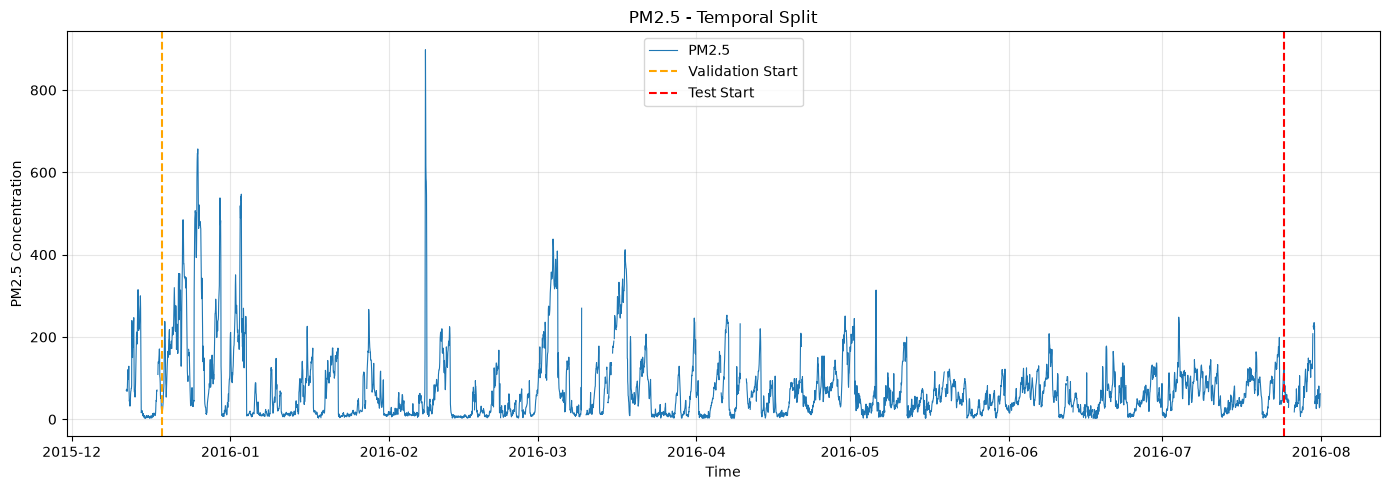

In [53]:
start = val_start_time - pd.Timedelta(days=7)
end = test_start_time + pd.Timedelta(days=7)

plot_df = df[
    (df["timestamp"] >= start) &
    (df["timestamp"] <= end)
]

plt.figure(figsize=(14, 5))

plt.plot(
    plot_df["timestamp"],
    plot_df["PM2.5"],
    label="PM2.5",
    linewidth=0.8
)

plt.axvline(val_start_time, color="orange",
            linestyle="--", label="Validation Start")

plt.axvline(test_start_time, color="red",
            linestyle="--", label="Test Start")

plt.title("PM2.5 - Temporal Split")
plt.xlabel("Time")
plt.ylabel("PM2.5 Concentration")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

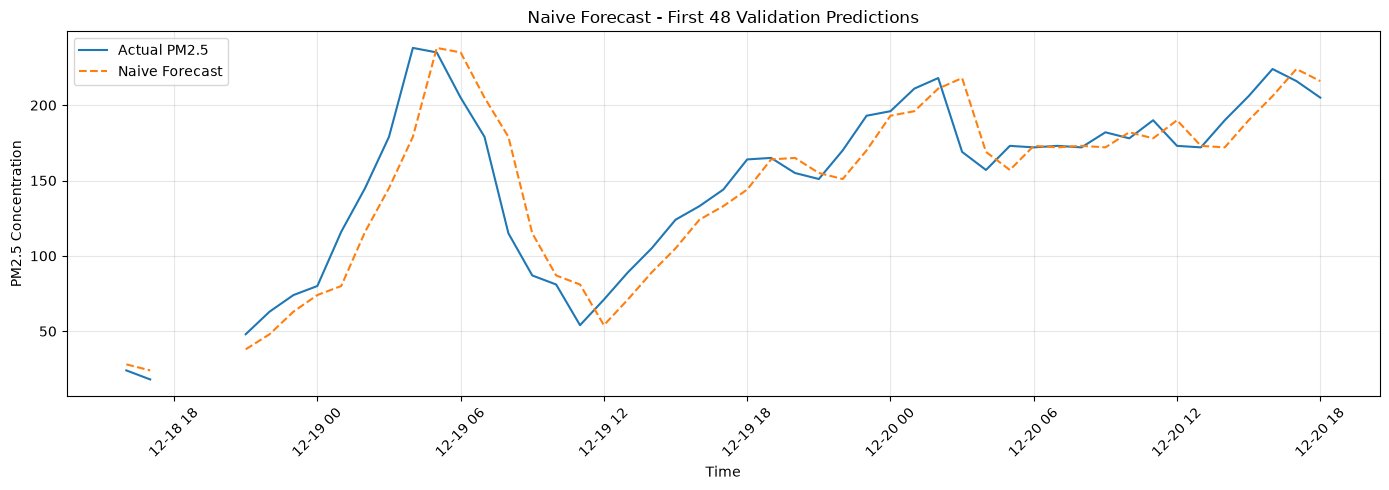

In [54]:
first_48 = (
    val_df.sort_values("target_timestamp")
    .head(48)
    .set_index("target_timestamp")
)

# Eksik saatleri grafikte boşluk olarak göster
hours = pd.date_range(
    first_48.index.min(),
    first_48.index.max(),
    freq="h"
)

first_48 = first_48.reindex(hours)

plt.figure(figsize=(14, 5))

plt.plot(
    first_48.index,
    first_48["target_pm25_next_hour"],
    label="Actual PM2.5"
)

plt.plot(
    first_48.index,
    first_48["naive_prediction"],
    label="Naive Forecast",
    linestyle="--"
)

plt.title("Naive Forecast - First 48 Validation Predictions")
plt.xlabel("Time")
plt.ylabel("PM2.5 Concentration")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [55]:
assert (
    train_df["target_timestamp"].max()
    < val_df["target_timestamp"].min()
), "Train ve Validation tarihleri çakışıyor!"

print("Kontrol 1: PASSED")

Kontrol 1: PASSED


In [56]:
test_df = valid_df[
    valid_df["target_timestamp"] >= test_start_time
].copy()

assert (
    val_df["target_timestamp"].max()
    < test_df["target_timestamp"].min()
), "Validation ve Test tarihleri çakışıyor!"

print("Kontrol 2: PASSED")

Kontrol 2: PASSED


In [57]:
assert (
    (
        valid_df["target_timestamp"] - valid_df["timestamp"]
    ) == pd.Timedelta(hours=1)
).all(), "Geçersiz hedef zamanı bulundu!"

print("Kontrol 3: PASSED")


Kontrol 3: PASSED


In [58]:
from pathlib import Path


reports_dir = Path("../reports")
reports_dir.mkdir(exist_ok=True)

y_true = val_df["target_pm25_next_hour"]
y_pred = val_df["naive_prediction"]

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

results = pd.DataFrame({
    "Model": ["Naive Forecast"],
    "Period": ["Validation"],
    "MAE": [round(mae, 2)],
    "RMSE": [round(rmse, 2)]
})

results.to_csv(
    reports_dir / "temporal_baseline.csv",
    index=False
)

print(results)

            Model      Period    MAE   RMSE
0  Naive Forecast  Validation  10.19  20.82
